<a href="https://colab.research.google.com/github/cs23f016/CSL701_CS25_Machine-Learning-Lab/blob/main/Copy_of_ML_Experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name :Ganesh Shankar Khadapkar

Batch :CS2


Roll Number :CS25



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print(df.head())
print("Dataset Shape:", df.shape)
print(df.info())
print(df.isnull().sum())

Saving Mall_Customers.csv to Mall_Customers.csv
Dataset loaded successfully!
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Dataset Shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtype

# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [3]:
features = df[['Annual Income (k$)', 'Spending Score (1-100)']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

print("Scaled Data (first 5 rows):")
print(X_scaled[:5])

Scaled Data (first 5 rows):
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

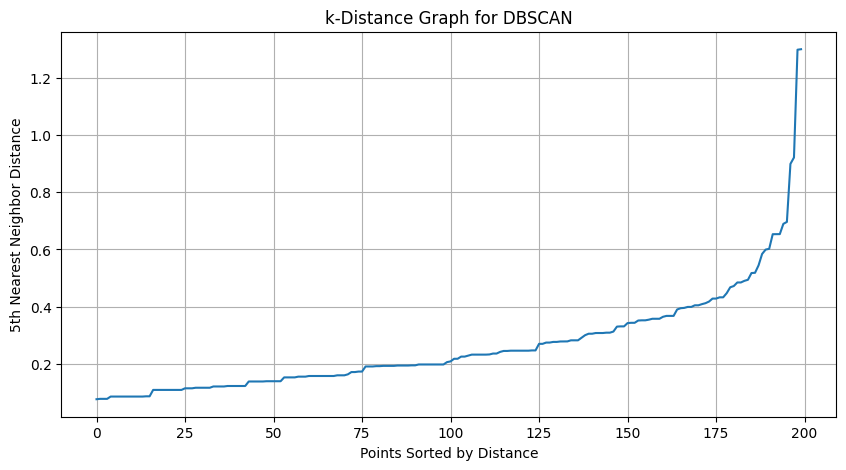

In [4]:
min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

k_distances = np.sort(distances[:, min_samples - 1])

plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.xlabel("Points Sorted by Distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.title("k-Distance Graph for DBSCAN")
plt.grid(True)
plt.show()

# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [5]:
eps_value = 0.5

dbscan = DBSCAN(eps=eps_value, min_samples=min_samples)
labels = dbscan.fit_predict(X_scaled)

df['Cluster'] = labels

print("Cluster Labels:")
print(df['Cluster'].value_counts().sort_index())

Cluster Labels:
Cluster
-1      8
 0    157
 1     35
Name: count, dtype: int64


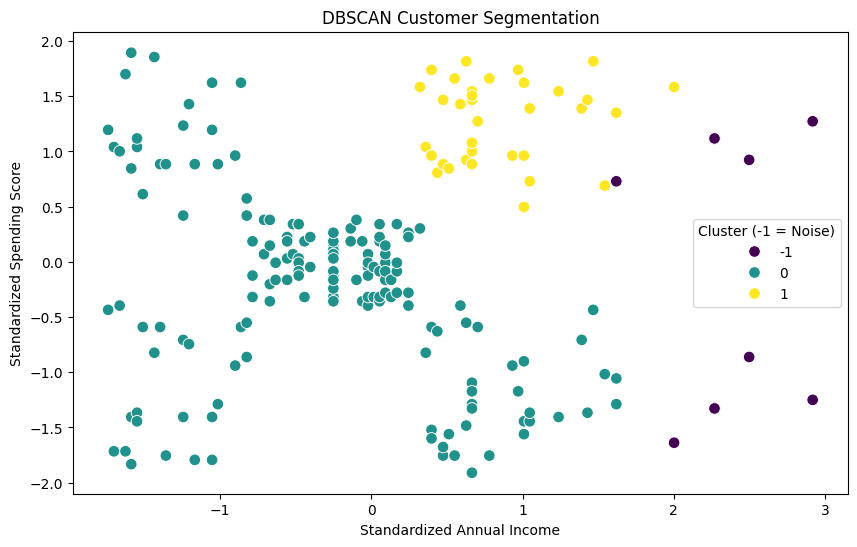

In [6]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    hue=labels,
    palette='viridis',
    s=70
)

plt.xlabel("Standardized Annual Income")
plt.ylabel("Standardized Spending Score")
plt.title("DBSCAN Customer Segmentation")
plt.legend(title="Cluster (-1 = Noise)")
plt.show()

# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [7]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print("Number of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)
print("Noise Percentage:", round(n_noise / len(labels) * 100, 2), "%")

non_noise = labels != -1
X_clustered = X_scaled[non_noise]
labels_clustered = labels[non_noise]

if len(set(labels_clustered)) >= 2:
    score = silhouette_score(X_clustered, labels_clustered)
    print("Silhouette Score:", round(score, 4))
else:
    print("Silhouette Score cannot be calculated because fewer than 2 non-noise clusters were found.")

Number of Clusters: 2
Number of Noise Points: 8
Noise Percentage: 4.0 %
Silhouette Score: 0.3876


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

In [8]:
print("Average Income and Spending Score by Cluster:")

cluster_stats = df.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2)

print(cluster_stats)

print("\nCustomers in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

print("\nNoise Points (Cluster -1):")
print(
    df[df['Cluster'] == -1][
        ['CustomerID', 'Annual Income (k$)', 'Spending Score (1-100)']
    ]
)

Average Income and Spending Score by Cluster:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
-1                   122.75                   46.88
 0                    52.49                   43.10
 1                    82.54                   82.80

Customers in Each Cluster:
Cluster
-1      8
 0    157
 1     35
Name: count, dtype: int64

Noise Points (Cluster -1):
     CustomerID  Annual Income (k$)  Spending Score (1-100)
191         192                 103                      69
192         193                 113                       8
194         195                 120                      16
195         196                 120                      79
196         197                 126                      28
197         198                 126                      74
198         199                 137                      18
199         200                 137                      83


# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.